# 12 · Write your own in-run writer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/12_python_writer.ipynb)

**Time:** 40 minutes · **Needs:** X-SCAPE (container, Mac wheel or source build) · **Data:** none: it runs X-SCAPE (20 O+O events, about half a minute)

The production scripts write fixed files: hadrons, the hydro on a grid, the jets' sources.
A question of your own often needs something else, and keeping a whole event to compute it
later is expensive: one O+O event's fluid evolution takes a few hundred MB in memory. An
**in-run writer** is Python code that sees each event while X-SCAPE still holds it, measures
what you need, and stores only that. This tutorial writes one:
- where in the event loop your code runs, and what it can reach there;
- a measurement of the fluid of each event: its temperature, entropy, shape and flow, at
  every time step;
- a small HDF5 writer that grows by one event at a time;
- 20 O+O events, the file read back, and what it shows: the cooling of the fireball against
  Bjorken's expectation, and the conversion of the initial shape into flow;
- the loop's cost and memory.

Reference pages: [The Pythonic interface](https://jhputschke.github.io/js-contrib/python/pythonic/),
[Writing modules in Python](https://jhputschke.github.io/js-contrib/python/modules/).

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/).
import os, sys
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


In [2]:
ok, missing = te.meets(['xscape'], env.caps)
assert ok, f"this tutorial needs {missing}: see 01_check_setup.ipynb"

## 1. Where your code runs

`js.per_event()` runs X-SCAPE one event at a time from Python. Each pass of the loop body comes
**after** X-SCAPE ran every module on the event (`ExecPerEvent()`) and **before** it frees the
event's memory (`ClearPerEvent()`):

```python
with js.per_event(main_xml, user_xml) as driver:      # Init() on entry, Finish() on exit
    for i in driver.events():                          # ExecPerEvent() ... ClearPerEvent()
        hydro = driver.hydro                           # the event is still in memory here
        ...                                            # measure, store
```

Inside the loop the modules hold the event: `driver.hydro` its fluid,
`driver.energy_loss_manager` its parton showers, `driver.soft_particlization` and
`driver.hadronization_manager` its hadrons. Whatever you want to keep, take it there. There
are three ways to write such code:

| | where it runs | example |
|---|---|---|
| code in the event loop | between `ExecPerEvent()` and `ClearPerEvent()` | this tutorial; `python_bulk_h5_writer.py` (its default mode) |
| a module in a pipeline built by hand | its `Exec()`, after the hydro in the task list | `jetscape.fast_h5_bulk.H5BulkWriter` |
| a `JetScapeWriter` subclass | `Write(obj)` for every parton, shower and hadron the modules write | `ToyWriter` in `python_modules/toy_modules.py` |

The loop is the simplest and works with the XML's own pipeline, so we use it. The other two
fit when you build the pipeline by hand, or want exactly what the modules write.

X-SCAPE's C++ code prints to the process's standard output and error. In Jupyter that would fill the
notebook, so `xscape_log()` sends it to a file while X-SCAPE runs:

In [3]:
import os, sys, time, ctypes
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import jetscape as js

@contextmanager
def xscape_log(path):
    """Send what C++ code prints (to file descriptors 1 and 2) to the file `path`."""
    libc = ctypes.CDLL(None)
    sys.stdout.flush(); sys.stderr.flush(); libc.fflush(None)
    saved = [os.dup(1), os.dup(2)]
    with open(path, "w") as f:
        os.dup2(f.fileno(), 1)
        os.dup2(f.fileno(), 2)
        try:
            yield
        finally:
            libc.fflush(None)
            for fd, copy in zip((1, 2), saved):
                os.dup2(copy, fd)
                os.close(copy)

## 2. The run: O+O fireballs without jets

We start from the user XML of the O+O example, `example/pythonic/oo_workflow.xml`: O+O
collisions at $\sqrt{s_{NN}} = 200$ GeV with impact parameters below 3 fm (central),
3dMCGlauber for the initial state, MUSIC (on the GPU where there is one) for the fluid. The
example also makes jets; we remove the hard process, the energy loss and both
hadronizations, and let 3dMCGlauber make its strings by itself, without a hard scattering
(`generateOnlyPositions` 0). What remains is the bulk: the initial state and the fluid.

In 3dMCGlauber each nucleon–nucleon collision makes **strings**, which deposit their energy
into the fluid over the first ~0.5 fm/c (MUSIC treats them as sources). MUSIC then evolves
the fluid, viscous, in $\tau$, $x$, $y$ and the space-time rapidity $\eta_s$, until every
cell has cooled below the freeze-out temperature $T_\text{fo} = 150$ MeV. With
`<output_evolution_to_memory>` 1 it hands the evolution to X-SCAPE, every 5th time step, in
memory: that is what our writer reads.

In [4]:
import xml.etree.ElementTree as ET
from jetscape import paths

os.makedirs("out/12_python_writer", exist_ok=True)
root = ET.parse(paths.examples_dir() / "pythonic" / "oo_workflow.xml").getroot()
for section in ("Hard", "Eloss", "JetHadronization", "SoftParticlization"):
    root.remove(root.find(section))                       # no jets, no hadrons
mc = root.find("IS/MCGlauber")
mc.find("generateOnlyPositions").text = "0"               # strings from the collisions alone
mc.find("Subtract_hard_momentum").text = "0"              # no hard scattering to subtract
root.find("nEvents").text = "20"
ET.ElementTree(root).write("out/12_python_writer/oo_hydro.xml")

print("sections:", [c.tag for c in root if len(c)])
print("events", root.find("nEvents").text, "| seed", root.find("Random/seed").text,
      "| b in", mc.find("b_min").text, "-", mc.find("b_max").text, "fm",
      "| MUSIC in memory:", root.find("Hydro/MUSIC/output_evolution_to_memory").text,
      "every", root.find("Hydro/MUSIC/output_evolution_every_N_timesteps").text, "steps")

sections: ['Random', 'IS', 'Preequilibrium', 'Hydro']
events 20 | seed 7 | b in 0.0 - 3.0 fm | MUSIC in memory: 1 every 5 steps


## 3. What to measure

`driver.hydro.get_bulk_info()` is the event's evolution: an `EvolutionHistory` on a grid in
$\tau$, $x$, $y$, $\eta_s$. With MUSIC's slim copy (`<slim_bulk_info>` 1) every cell is a
record of a few fields (`data_info`), and `data_vector_numpy()` shows the whole store as a
numpy array **without copying it**. The view is only valid while X-SCAPE holds the event:
use it inside the loop, and copy what you keep.

At midrapidity ($\eta_s = 0$) and every stored time step we measure:
- **the hottest cell**: its temperature $T_\text{max}(\tau)$ and entropy density
  $s_\text{max}(\tau)$;
- **the entropy and energy per unit rapidity** that flow through the slice,
  $dS/d\eta_s = \tau\int s\,\gamma\,dx\,dy$ and $dE/d\eta_s = \tau\int T^{\tau\tau}\,dx\,dy$.
  The factor $\tau$ is the volume element ($dV = \tau\,dx\,dy\,d\eta_s$), $\gamma$ the Lorentz
  factor of the flow, and $T^{\tau\tau} = (e + P)\gamma^2 - P$ the energy density in the
  collision frame, with $e + P = Ts$ (no net baryon density here). That is the ideal-fluid
  part: the viscous stresses are not in the slim copy.
- **the eccentricity** of the energy density, $\varepsilon_2 = |\int r^2 e^{2i\phi} e\,dx\,dy|
  \,/\int r^2 e\,dx\,dy$, about its centre: 0 for a round fireball, larger for an elongated one;
- **the mean transverse flow velocity** $\langle v_T\rangle$, weighted by the energy density.

These are a few numbers per time step: about 1 kB per event instead of a few hundred MB.

In [5]:
def measure(bulk):
    """Per stored tau step, at eta_s = 0: tau, T_max, s_max, dS/deta, dE/deta, eps2, <v_T>."""
    assert bulk.uses_data_vector(), "needs MUSIC's slim copy: <Hydro><MUSIC><slim_bulk_info> 1"
    names = list(bulk.data_info)        # energy_density, entropy_density, temperature, vx, vy, vz
    cells = bulk.data_vector_numpy().reshape(bulk.ntau, bulk.nx, bulk.ny, bulk.neta, len(names))
    k0 = int(round(-bulk.eta_min / bulk.deta))                  # the eta_s = 0 slice
    mid = cells[:, :, :, k0, :]                                  # still a view: no copy
    e, s, T, vx, vy, vz = (mid[..., names.index(n)] for n in
                           ("energy_density", "entropy_density", "temperature", "vx", "vy", "vz"))
    gamma2 = 1 / (1 - (vx**2 + vy**2 + vz**2))                  # Lorentz factor squared
    T_tautau = e + T * s * (gamma2 - 1)                          # (e + P) gamma^2 - P, e + P = T s

    tau = bulk.tau_min + bulk.dtau * np.arange(bulk.ntau)
    x = bulk.x_min + bulk.dx * np.arange(bulk.nx)
    y = bulk.y_min + bulk.dy * np.arange(bulk.ny)
    X, Y = np.meshgrid(x, y, indexing="ij")
    dA = bulk.dx * bulk.dy
    E = e.sum(axis=(1, 2))                                       # per tau step
    with np.errstate(invalid="ignore", divide="ignore"):         # empty first step: nan
        xc = (e * X).sum(axis=(1, 2)) / E
        yc = (e * Y).sum(axis=(1, 2)) / E
        z = (X - xc[:, None, None]) + 1j * (Y - yc[:, None, None])
        eps2 = np.abs((e * z**2).sum(axis=(1, 2))) / (e * np.abs(z)**2).sum(axis=(1, 2))
        vT = (e * np.hypot(vx, vy)).sum(axis=(1, 2)) / E
    return {"tau": tau, "T_max": T.max(axis=(1, 2)), "s_max": s.max(axis=(1, 2)),
            "dS_deta": tau * (s * np.sqrt(gamma2)).sum(axis=(1, 2)) * dA,
            "dE_deta": tau * T_tautau.sum(axis=(1, 2)) * dA, "eps2": eps2, "vT": vT}


def glauber():
    """This event's 3dMCGlauber numbers: the last line of events_summary.dat, which it
    writes into the working directory (as example/pythonic/oo_workflow.py reads it)."""
    with open("events_summary.dat") as f:
        rows = [line.split() for line in f if line.strip() and not line.startswith("#")]
    _, npart, ncoll, nstrings, b = rows[-1][:5]
    return {"npart": int(npart), "ncoll": int(ncoll), "nstrings": int(nstrings), "b": float(b)}

## 4. The writer

The writer keeps one HDF5 file open and grows it by one event at a time, in the layout the
production files use: flat arrays and offsets.

- `events/<name>`: one value per event (the Glauber numbers, the lifetime, ...);
- `frames/<name>`: one value per time step, the events one after the other;
- `frames/offsets`: event $i$ is `frames[offsets[i]:offsets[i+1]]`. Events have different
  numbers of time steps (a larger fireball lives longer), so a rectangular array would not fit.

Every dataset is resizable (`maxshape=(None,)`). HDF5 stores a resizable dataset in
**chunks**, blocks of a fixed number of values that it reads and writes as a whole; ours are
small (256 values per event field, 4096 per frame field). The file is flushed after every
event, so what was written is on disk even if a later event crashes the run. The run's XML and seed go
into the file's attributes: the file says how it was made.

In [6]:
import h5py

class HistoryWriter:
    """An HDF5 file that grows by one event at a time (events/, frames/, frames/offsets)."""

    def __init__(self, path, attrs=None):
        self.f = h5py.File(path, "w")
        self.f.attrs.update(attrs or {})
        self.f.create_dataset("frames/offsets", data=[0], maxshape=(None,), chunks=(1024,), dtype="i8")
        self.n_events = 0

    def _extend(self, name, values, dtype):
        if name not in self.f:
            chunk = 256 if name.startswith("events/") else 4096    # values per HDF5 chunk
            self.f.create_dataset(name, shape=(0,), maxshape=(None,), chunks=(chunk,), dtype=dtype)
        d = self.f[name]
        n = len(d)
        d.resize((n + len(values),))
        d[n:] = values

    def append(self, scalars, frames):
        """One event: `scalars` {name: value}, `frames` {name: array, one value per tau step}."""
        n = {len(v) for v in frames.values()}
        assert len(n) == 1, "every frame series needs one value per tau step"
        for name, value in scalars.items():
            self._extend(f"events/{name}", [value], np.asarray(value).dtype)
        for name, values in frames.items():
            self._extend(f"frames/{name}", np.asarray(values, dtype="f4"), "f4")
        off = self.f["frames/offsets"]
        off.resize((len(off) + 1,))
        off[-1] = off[-2] + n.pop()
        self.n_events += 1
        self.f.flush()                    # on disk now

    def close(self):
        self.f.attrs["n_events"] = self.n_events
        self.f.close()

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()

## 5. The run

`js.JobDir` gives the run a working directory of its own (`out/12_python_writer/work/oo_hydro`): MUSIC and
3dMCGlauber read their inputs from and write side files to the current directory. It changes
into that directory for the run, so **every path you write to must be absolute**, like
`h5_path` here.

In the loop, per event: the measurement, the Glauber numbers, the writer. For event 0 we also
keep the temperature map at $\eta_s = 0$ at three times, to see what `measure()` sees. They are
copies (`.copy()`): the view itself dies with the event. The loop also times itself.

In [7]:
h5_path = Path("out/12_python_writer/oo_history.h5").resolve()          # absolute: JobDir changes directory
xml_text = Path("out/12_python_writer/oo_hydro.xml").read_text()
attrs = {"xml": xml_text, "seed": int(root.find("Random/seed").text), "eta_s": 0.0,
         "units": "tau fm/c, T_max GeV, s_max 1/fm^3, dS_deta 1, dE_deta GeV, vT c, b fm, tau_end fm/c"}

import resource
rss_unit = 1 if sys.platform == "darwin" else 1024          # ru_maxrss: bytes on macOS, kB on Linux
t_event, t_measure, peak_rss, maps = [], [], [], {}
with xscape_log("out/12_python_writer/oo_hydro.log"), js.JobDir("out/12_python_writer", "out/12_python_writer/oo_hydro.xml") as job, \
        HistoryWriter(h5_path, attrs) as writer:
    with js.per_event(job.main_xml, job.user_xml) as driver:
        t0 = time.time()
        for i in driver.events():
            t1 = time.time()
            bulk = driver.hydro.get_bulk_info()
            frames = measure(bulk)
            writer.append({"event": i, **glauber(), "tau_end": frames["tau"][-1],
                           "ntau": bulk.ntau, "hit_grid_boundary": driver.hydro.get_hit_grid_boundary()},
                          frames)
            if i == 0:
                names = list(bulk.data_info)
                print("tasks:", [type(t).__name__ for t in driver.GetTaskList()])
                print(f"grid: {bulk.nx} x {bulk.ny} x {bulk.neta} cells (x, y, eta_s) x {bulk.ntau} tau steps,"
                      f" dtau = {bulk.dtau:.2f} fm/c; fields {names}")
                event_bytes = bulk.get_data_size() * len(names) * 4
                print(f"event 0 in memory: {event_bytes / 1e6:.0f} MB; a view of it costs nothing:",
                      np.shares_memory(bulk.data_vector_numpy(), bulk.data_vector_numpy()))
                cells = bulk.data_vector_numpy().reshape(bulk.ntau, bulk.nx, bulk.ny, bulk.neta, len(names))
                k0 = int(round(-bulk.eta_min / bulk.deta))
                for tau in (0.6, 1.5, 3.0):
                    j = int(round((tau - bulk.tau_min) / bulk.dtau))
                    maps[tau] = cells[j, :, :, k0, names.index("temperature")].copy()
                extent = [bulk.x_min, bulk.x_min + bulk.dx * (bulk.nx - 1),
                          bulk.y_min, bulk.y_min + bulk.dy * (bulk.ny - 1)]
            t2 = time.time()
            t_event.append(t1 - t0)
            t_measure.append(t2 - t1)
            peak_rss.append(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * rss_unit / 1e9)
            t0 = t2
print(f"{writer.n_events} events: X-SCAPE {np.mean(t_event):.2f} s per event, measuring and writing"
      f" {1e3 * np.mean(t_measure):.0f} ms per event")
print("peak memory of this process after events 1, 5, 10, 20:",
      [f"{peak_rss[k - 1]:.2f} GB" for k in (1, 5, 10, 20)])
with h5py.File(h5_path, "r") as f:
    data_kB = sum(f[g][k].nbytes for g in ("events", "frames") for k in f[g]) / 1e3
print(f"file: {h5_path.stat().st_size / 1e3:.0f} kB on disk, of which {data_kB:.0f} kB are values"
      f" ({1e3 * data_kB / writer.n_events:.0f} bytes per event)")

tasks: ['InitialState', 'PreequilibriumDynamics', 'MpiMusic']
grid: 70 x 70 x 60 cells (x, y, eta_s) x 40 tau steps, dtau = 0.10 fm/c; fields ['energy_density', 'entropy_density', 'temperature', 'vx', 'vy', 'vz']
event 0 in memory: 282 MB; a view of it costs nothing: True


20 events: X-SCAPE 0.96 s per event, measuring and writing 16 ms per event
peak memory of this process after events 1, 5, 10, 20: ['1.46 GB', '2.44 GB', '2.74 GB', '3.00 GB']
file: 192 kB on disk, of which 23 kB are values (1160 bytes per event)


**What to notice.**

- **The pipeline is the XML's:** the initial state (3dMCGlauber), a pre-equilibrium stage that
  does nothing here, and MUSIC.
- **One event is big in memory, small on disk.** Event 0's evolution holds 282 MB: 70 × 70 × 60
  cells, 40 stored steps, six fields. We keep about 1 kB of it. The file on disk is larger than
  its values because HDF5 reserves whole chunks.
- **The measurement is cheap:** about 13 ms per event against 0.85 s for X-SCAPE.
- **The process's memory grows during the run**, from a peak of 1.5 GB after the first event to
  more than 3 GB after 20. Our loop keeps about 1 kB per event, so this is X-SCAPE's own memory (the
  modules, MUSIC's stores, the memory allocator), not the writer's; exercise 3 shows how to check.
  For long runs, watch it, and split them into several jobs if it keeps growing.

The temperature maps of event 0 kept above:

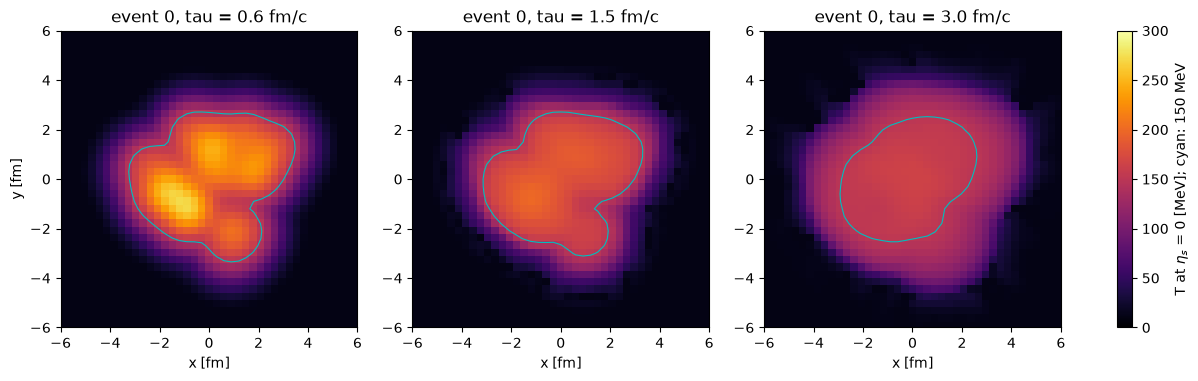

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
for ax, (tau, Tmap) in zip(axes, maps.items()):
    im = ax.imshow(1e3 * Tmap.T, origin="lower", extent=extent, cmap="inferno", vmin=0, vmax=300)
    ax.contour(np.linspace(extent[0], extent[1], Tmap.shape[0]), np.linspace(extent[2], extent[3], Tmap.shape[1]),
               Tmap.T, levels=[0.15], colors="c", linewidths=0.8)
    ax.set(xlim=(-6, 6), ylim=(-6, 6), title=f"event 0, tau = {tau} fm/c", xlabel="x [fm]")
axes[0].set_ylabel("y [fm]")
fig.colorbar(im, ax=axes, label=r"T at $\eta_s$ = 0 [MeV]; cyan: 150 MeV");

**What to notice.** At 0.6 fm/c the fireball is lumpy: hot spots of up to about 300 MeV
where nucleons collided, a fluctuating shape. By 1.5 fm/c pressure has smoothed the hot spots
out, and by 3 fm/c the fireball is a rounder blob of about 170 MeV. The region above 150 MeV
(cyan) keeps about the same size while the temperature inside it falls: the fluid streams
outward and cools as it goes. This event's fluid is below 150 MeV everywhere after 4.4 fm/c.

## 6. Read it back

The file is ordinary HDF5: any program reads it. Its offsets split the frames into events:

In [9]:
with h5py.File(h5_path, "r") as f:
    print("datasets:", sorted(f["events"]), "|", sorted(f["frames"]))
    print("attributes:", {k: (v if k != "xml" else f"<{len(v)} characters>") for k, v in f.attrs.items()})
    ev = {k: f["events"][k][:] for k in f["events"]}
    frames = {k: f["frames"][k][:] for k in f["frames"]}
offsets = frames.pop("offsets")
n_ev = len(offsets) - 1
per_event = [{k: v[offsets[i]:offsets[i + 1]] for k, v in frames.items()} for i in range(n_ev)]

import pandas as pd
print(f"{n_ev} events: N_part {ev['npart'].min()}-{ev['npart'].max()}, b {ev['b'].min():.1f}-{ev['b'].max():.1f} fm,"
      f" last step {ev['tau_end'].min():.1f}-{ev['tau_end'].max():.1f} fm/c; {len(frames['tau'])} frames;"
      f" any event at the grid's edge: {bool(ev['hit_grid_boundary'].any())}")
pd.DataFrame(ev).set_index("event").head(8)

datasets: ['b', 'event', 'hit_grid_boundary', 'ncoll', 'npart', 'nstrings', 'ntau', 'tau_end'] | ['T_max', 'dE_deta', 'dS_deta', 'eps2', 'offsets', 's_max', 'tau', 'vT']
attributes: {'eta_s': np.float64(0.0), 'n_events': np.int64(20), 'seed': np.int64(7), 'units': 'tau fm/c, T_max GeV, s_max 1/fm^3, dS_deta 1, dE_deta GeV, vT c, b fm, tau_end fm/c', 'xml': '<5370 characters>'}


20 events: N_part 13-27, b 0.8-2.9 fm, last step 3.4-5.1 fm/c; 782 frames; any event at the grid's edge: False


,b,hit_grid_boundary,ncoll,npart,nstrings,ntau,tau_end
event,,,,,,,
0,1.355600,False,24,26,30,40,4.38
1,1.834390,False,25,24,26,38,4.18
2,0.842950,False,36,26,39,47,5.08
3,2.887460,False,15,14,18,35,3.88
4,1.304270,False,25,27,34,46,4.98
5,2.513870,False,20,17,21,39,4.28
6,1.166410,False,18,20,21,36,3.98
7,0.952073,False,20,20,26,39,4.28


**What to notice.** The file holds what the loop wrote, with the run's XML and seed as
attributes. The 20 events span $N_\text{part}$ = 13–27, and their fluid lives 3.4–5.1 fm/c:
different numbers of time steps, which the offsets handle. No event reached the edge of the
grid (MUSIC would then have stopped early).

## 7. How the fireball cools

The simplest picture of the fluid at midrapidity is **Bjorken's**: a fluid that expands only
along the beam, with the same rapidity everywhere (boost invariance), ideal (no viscosity),
with a conformal equation of state ($P = e/3$). Then:
- entropy is conserved in each rapidity slice: $s\tau$ = const in every cell, and $dS/d\eta_s$ is
  constant;
- the energy per rapidity falls, because the fluid does work on its neighbours along the beam:
  $e \propto \tau^{-4/3}$, so $dE/d\eta_s \propto \tau^{-1/3}$;
- the temperature falls as $T \propto \tau^{-1/3}$ (from $s \propto T^3$).

A real fireball differs: it also expands **transversely**, it is viscous, its equation of state
is not conformal near $T_\text{fo}$, and it is not boost invariant. Our 20 events show how much
that matters:

T_max(3 fm/c) / T_max(1 fm/c): 0.685 (events 0.633 - 0.729); Bjorken 0.693
dS_deta(3 fm/c) / dS_deta(1 fm/c): 1.296 (events 1.235 - 1.323); Bjorken 1.000
dE_deta(3 fm/c) / dE_deta(1 fm/c): 1.059 (events 0.997 - 1.085); Bjorken 0.693
tau s_max, same ratio: 0.471 (events 0.360 - 0.615); Bjorken 1.000
s/T^3 in the hottest cell: at tau = 0.58 fm/c 14.4 | at the last step 4.2


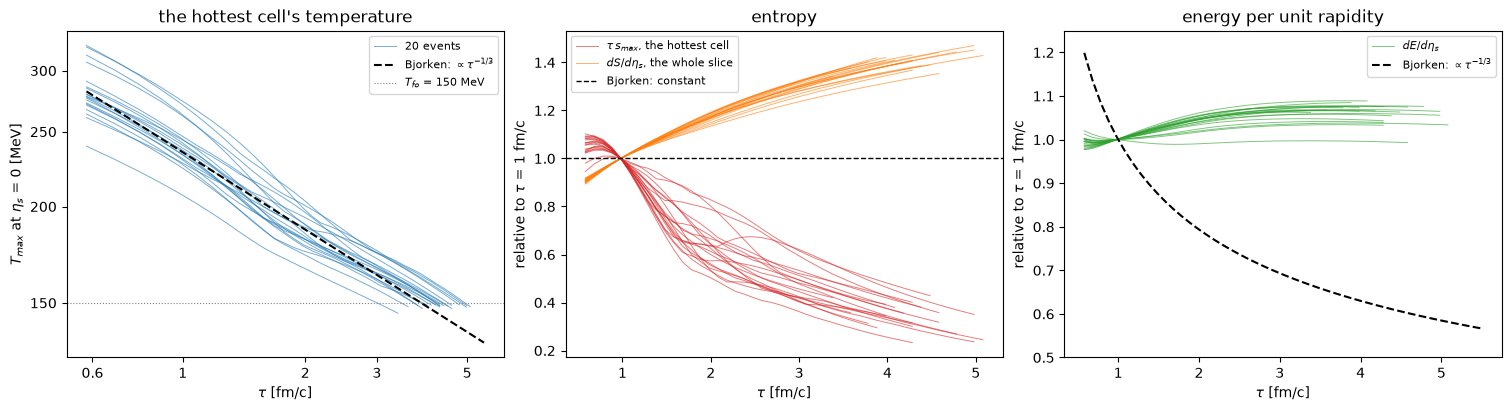

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
tau_ref = 0.58                                              # the first stored step with a fluid
at = lambda f, tau: np.argmin(abs(f["tau"] - tau))          # the step closest to tau
tt = np.linspace(tau_ref, 5.5, 50)
for i, f in enumerate(per_event):
    ok = f["tau"] >= tau_ref - 0.01                          # from the first step with a fluid
    lab = (lambda text: text if i == 0 else None)
    ax[0].plot(f["tau"][ok], 1e3 * f["T_max"][ok], color="C0", lw=0.7, alpha=0.6, label=lab("20 events"))
    j = at(f, 1.0)
    ts = f["tau"] * f["s_max"]
    ax[1].plot(f["tau"][ok], (ts / ts[j])[ok], color="C3", lw=0.7, alpha=0.6, label=lab(r"$\tau\,s_{max}$, the hottest cell"))
    ax[1].plot(f["tau"][ok], (f["dS_deta"] / f["dS_deta"][j])[ok], color="C1", lw=0.7, alpha=0.6,
               label=lab(r"$dS/d\eta_s$, the whole slice"))
    ax[2].plot(f["tau"][ok], (f["dE_deta"] / f["dE_deta"][j])[ok], color="C2", lw=0.7, alpha=0.6,
               label=lab(r"$dE/d\eta_s$"))
T_ref = np.mean([f["T_max"][at(f, tau_ref)] for f in per_event])
ax[0].plot(tt, 1e3 * T_ref * (tt / tau_ref) ** (-1 / 3), "k--", label=r"Bjorken: $\propto\tau^{-1/3}$")
ax[0].axhline(150, color="0.5", lw=0.8, ls=":", label=r"$T_{fo}$ = 150 MeV")
ax[0].set(xscale="log", yscale="log", xlabel=r"$\tau$ [fm/c]", ylabel=r"$T_{max}$ at $\eta_s$ = 0 [MeV]",
          title="the hottest cell's temperature")
ax[0].set_yticks([150, 200, 250, 300], ["150", "200", "250", "300"]); ax[0].minorticks_off()
ax[0].set_xticks([0.6, 1, 2, 3, 5], ["0.6", "1", "2", "3", "5"])
ax[1].axhline(1, color="k", lw=1, ls="--", label="Bjorken: constant")
ax[1].set(xlabel=r"$\tau$ [fm/c]", ylabel=r"relative to $\tau$ = 1 fm/c", title="entropy")
ax[2].plot(tt, tt ** (-1 / 3), "k--", label=r"Bjorken: $\propto\tau^{-1/3}$")
ax[2].set(xlabel=r"$\tau$ [fm/c]", ylabel=r"relative to $\tau$ = 1 fm/c", title="energy per unit rapidity",
          ylim=(0.5, 1.25))
for a in ax:
    a.legend(fontsize=8)

hbarc = 0.19733                                             # GeV fm: T in 1/fm is T / hbarc
ratio = lambda name, f: f[name][at(f, 3.0)] / f[name][at(f, 1.0)]
for name, bj in [("T_max", 3 ** (-1 / 3)), ("dS_deta", 1.0), ("dE_deta", 3 ** (-1 / 3))]:
    r = [ratio(name, f) for f in per_event]
    print(f"{name}(3 fm/c) / {name}(1 fm/c): {np.mean(r):.3f} (events {np.min(r):.3f} - {np.max(r):.3f}); Bjorken {bj:.3f}")
r = [ratio("s_max", f) * 3 for f in per_event]
print(f"tau s_max, same ratio: {np.mean(r):.3f} (events {np.min(r):.3f} - {np.max(r):.3f}); Bjorken 1.000")
sT3 = lambda f, k: f["s_max"][k] / (f["T_max"][k] / hbarc) ** 3
print("s/T^3 in the hottest cell: at tau = 0.58 fm/c", round(np.mean([sT3(f, at(f, tau_ref)) for f in per_event]), 1),
      "| at the last step", round(np.mean([sT3(f, -1) for f in per_event]), 1))

**What to notice.**

- **The hottest cell cools as $\tau^{-1/3}$**, as Bjorken's fluid does: between 1 and 3 fm/c its
  temperature falls by a factor 0.685 on average, against 0.693. It starts between 240 and
  320 MeV and reaches 150 MeV after 3–5 fm/c.
- **But not for Bjorken's reasons.** In that cell, $\tau s$ falls to about half (0.47) between 1
  and 3 fm/c instead of staying constant: the core empties faster, because the fluid also
  flows outward. That the temperature still follows $\tau^{-1/3}$ is the equation of state:
  $s/T^3$ drops from 14 in the hot start to 4 at the end (the crossover from quark–gluon plasma
  to hadron gas), so the same loss of entropy costs less temperature than $s \propto T^3$ would.
  The agreement is two effects that happen to cancel.
- **Entropy is produced.** $dS/d\eta_s$ grows by about 30 % between 1 and 3 fm/c, in every
  event. Ideal fluids conserve entropy; viscous ones turn the expansion into heat.
- **The energy per rapidity hardly falls.** $dE/d\eta_s$ stays within 10 % of its value at
  1 fm/c (6 % higher at 3 fm/c), where Bjorken's ideal fluid loses 31 %. The work along the beam
  comes from the longitudinal pressure, and shear viscosity lowers it, strongly in a small,
  hot, fast-expanding fireball. In this setup $\eta/s$ also grows with temperature
  (`shear_viscosity_3_*` in the XML: 0.108 at 206 MeV, rising above). Two caveats for the
  small rise: our $T^{\tau\tau}$ omits the viscous stresses, and in a 3D fluid energy can move
  between rapidity slices.

## 8. From shape to flow

A collision at finite impact parameter, and the random positions of the nucleons, make the
initial fireball elongated: $\varepsilon_2 > 0$. The pressure gradient is steeper along the
short axis, so the fluid accelerates faster there. Over time the flow makes the fireball
rounder, and the anisotropy moves from the shape into the momenta: the origin of elliptic flow
$v_2$ in the hadrons.

initial eps2: [0.33 0.45 0.13 0.45 0.2  0.33 0.32 0.28 0.09 0.26 0.19 0.66 0.1  0.08
 0.13 0.74 0.31 0.48 0.2  0.23]
eps2 at the last step / initial: 0.44 on average; <v_T> at the last step: 0.36
correlation of N_part with the lifetime: 0.84 | with initial eps2: -0.38


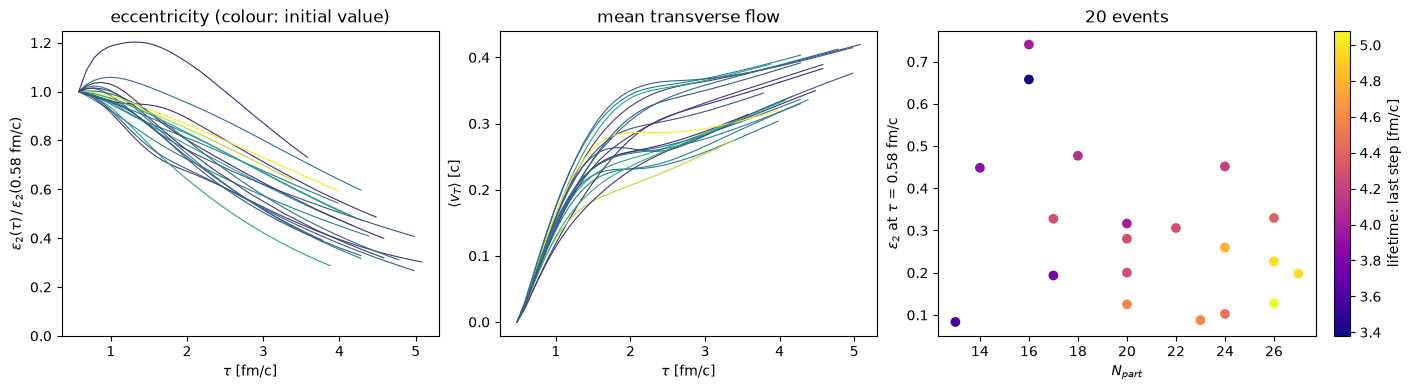

In [11]:
eps2_0 = np.array([f["eps2"][at(f, tau_ref)] for f in per_event])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for i, f in enumerate(per_event):
    c = plt.cm.viridis(eps2_0[i] / eps2_0.max())
    ok = f["tau"] >= tau_ref - 0.01
    ax[0].plot(f["tau"][ok], (f["eps2"] / eps2_0[i])[ok], color=c, lw=0.8)
    ax[1].plot(f["tau"], f["vT"], color=c, lw=0.8)
ax[0].set(xlabel=r"$\tau$ [fm/c]", ylabel=r"$\varepsilon_2(\tau)\,/\,\varepsilon_2(0.58$ fm/c$)$",
          title="eccentricity (colour: initial value)", ylim=(0, None))
ax[1].set(xlabel=r"$\tau$ [fm/c]", ylabel=r"$\langle v_T\rangle$ [c]", title="mean transverse flow")
sc = ax[2].scatter(ev["npart"], eps2_0, c=ev["tau_end"], cmap="plasma")
fig.colorbar(sc, ax=ax[2], label="lifetime: last step [fm/c]")
ax[2].set(xlabel=r"$N_{part}$", ylabel=r"$\varepsilon_2$ at $\tau$ = 0.58 fm/c", title="20 events")
print("initial eps2:", np.round(eps2_0, 2))
print(f"eps2 at the last step / initial: {np.mean([f['eps2'][-1] / e for f, e in zip(per_event, eps2_0)]):.2f} on average;"
      f" <v_T> at the last step: {np.mean([f['vT'][-1] for f in per_event]):.2f}")
print("correlation of N_part with the lifetime:", round(np.corrcoef(ev["npart"], ev["tau_end"])[0, 1], 2),
      "| with initial eps2:", round(np.corrcoef(ev["npart"], eps2_0)[0, 1], 2))

**What to notice.**

- **The initial eccentricities are large and varied**, 0.08 to 0.74. At impact parameters below
  3 fm the overlap of two oxygen nuclei is nearly round: the shape comes mostly from where the
  few nucleons happened to be. The two most eccentric events are small ones ($N_\text{part}$ = 16),
  and $\varepsilon_2$ is only weakly anti-correlated with $N_\text{part}$ ($r = -0.38$).
- **The eccentricity falls as the flow builds up.** By the last step it is down to 0.44 of its
  initial value on average, while $\langle v_T\rangle$ grows from 0 to about 0.36. A few events
  that start nearly round first become more eccentric (the dark curve that rises to 1.2): the
  hot spots reshape the fireball before the overall flow takes over.
- **Bigger systems live longer:** the lifetime follows $N_\text{part}$ closely ($r = 0.84$).

## 9. The per-event loop: cost and memory

What made this writer cheap, and what to keep in mind for your own:

- **Measure inside the loop, keep numbers.** The loop body runs while the event is in memory;
  after it, X-SCAPE frees the event. Here the measurement and the writing took about 1.5 % of
  the time X-SCAPE needed per event, and added about 1 kB per event to what the process holds.
- **Views, not copies.** `data_vector_numpy()` shows the event's 282 MB without copying them,
  and `cells[:, :, :, k0, :]` is still a view. `to_numpy_full()` would copy the whole event.
  The arrays `measure()` computes are of the size of one $\eta_s$ slice.
- **Copy what you keep.** A view dies with the event; keep `.copy()`s (the maps) or numbers.
- **Write as you go.** Appending and flushing per event costs little and loses nothing if the
  run stops. The offsets let events have different lengths.
- **Absolute paths.** `JobDir` changes the working directory for the run.
- **One run per process.** X-SCAPE keeps its configuration in process-wide singletons: for a
  second configuration, start a new process (as tutorial 11 does).
- **Writers and the XML's pipeline.** With the XML's own task list, add only writers with
  `driver.Add()`; a pipeline built by hand needs `<enableAutomaticTaskListDetermination>`
  false, or X-SCAPE builds a second one (see `python_bulk_h5_writer.py`).

### Check your result

In [12]:
import json
exp = json.load(open("expected/12_python_writer.json"))
assert n_ev == exp["n_events"]
# the Glauber stage is exact for the seed; the hydro (on a GPU) can differ slightly between setups
np.testing.assert_array_equal(ev["npart"], exp["npart"])
np.testing.assert_allclose(ev["tau_end"], exp["tau_end"], atol=0.11)            # one stored frame
np.testing.assert_allclose([f["T_max"].max() for f in per_event], exp["T_peak"], rtol=0.01)
np.testing.assert_allclose(eps2_0, exp["eps2_initial"], atol=0.01)
# what the file holds is what the loop measured
assert offsets[-1] == len(frames["tau"]) and len(offsets) == n_ev + 1
print("All checks pass.")

All checks pass.


## Exercises

1. **The hot volume.** Add to `measure()` the area at $\eta_s = 0$ where $T > 150$ MeV, per time
   step. When is it largest? Compare with the lifetime.
2. **Momentum anisotropy.** The flow's anisotropy is
   $\varepsilon_p = \int(T^{xx} - T^{yy}) / \int(T^{xx} + T^{yy})$ with, for an ideal fluid,
   $T^{ij} = (e + P)\gamma^2 v^i v^j + P\delta^{ij}$. Use $P = Ts - e$ (as `measure()` does) and add $\varepsilon_p(\tau)$:
   does it grow while $\varepsilon_2$ falls?
3. **Whose memory?** Run the same 20 events in a new process with an empty loop body and print
   the process's memory after each event (`psutil.Process().memory_info().rss`, or
   `ps -o rss= -p <pid>`). Does it grow as much without `measure()` and the writer?
4. **The final partons of a jet run.** Keep the jets in the XML (do not remove `Hard` and
   `Eloss`), and record per event `driver.energy_loss_manager.final_parton_array()`: flat
   records, with offsets per event, in the same writer.

## Next steps

- The production's own writers and files: [The Pythonic interface](https://jhputschke.github.io/js-contrib/python/pythonic/) (hadron files) and `example/python_bulk_h5_writer.py` (the whole hydro evolution).
- Writers and other stages as modules: [Writing modules in Python](https://jhputschke.github.io/js-contrib/python/modules/), and tutorial 11.
- The hydro of a production, for many events: tutorial 06 and [Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/).
- Bulk observables and flow in the hadrons: tutorial 13, and [The physics](https://jhputschke.github.io/js-contrib/about/physics/).